# Exploratory Data Analysis (EDA) & Data Preprocessing
## Sistem Prediksi Stok & Business Intelligence "Bakso Lintang"
**Dataset:** `sales_report.csv` (Laporan Transaksi Kasir APOS)  
**Periode Data:** Januari 2026 – September 2026  
**Acuan Proyek:** [PRD.md](PRD.md) (v1.1)

---

### Objektif & Keterkaitan dengan PRD:
1. **Validasi Data APOS (FR-01, FR-02)**: Memeriksa struktur, tipe data, dan kelengkapan kolom dari file ekspor APOS.
2. **Pembersihan Data Terstruktur (Data Cleaning)**:
   - Menghapus kolom yang 100% kosong (`Variant`, `SKU`, `Served By`).
   - Memvalidasi tipe numerik kolom finansial dan kuantitas.
   - Konversi format tanggal dan jam transaksi menjadi standar `Datetime`.
3. **Rekayasa Fitur Waktu (*Feature Engineering*)**: Menyiapkan atribut waktu (`Year_Month`, `Day_Name`, `Hour`, `Is_Weekend`) untuk analisis pola dan input model *time-series forecasting*.
4. **Ringkasan Metrik Bisnis & Finansial (FR-07)**: Menghitung total omset kotor, diskon, refund, omset bersih, serta *Average Order Value* (AOV).
5. **Analisis Menu Terlaris & Kategori (FR-04)**: Mengidentifikasi menu prioritas (*hero products*) untuk kebutuhan prediksi porsi harian dan konversi resep (*Bill of Materials* - BOM).
6. **Agregasi Penjualan Harian**: Membentuk tabel penjualan per menu per hari sebagai fondasi pemodelan *forecasting* 7 hari ke depan.


## 1. Setup & Import Libraries
Mengimpor library standar untuk pengolahan data (`pandas`, `numpy`) dan visualisasi (`matplotlib`, `seaborn`).


In [1]:
# Jalankan jika library belum terpasang di environment Anda:
# %pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Setup library selesai. Siap memproses data.")


Setup library selesai. Siap memproses data.


## 2. Memuat Dataset (Data Loading - PRD FR-01)
Membaca file laporan penjualan harian kasir APOS (`sales_report.csv`).


In [2]:
# Membaca dataset penjualan
df = pd.read_csv('sales_report.csv')

print(f"Total baris : {df.shape[0]:,} baris")
print(f"Total kolom : {df.shape[1]} kolom")
df.head(5)


Total baris : 64,327 baris
Total kolom : 25 kolom


,Outlet,Receipt Number,Date,Time,Category,Brand,Items,Variant,SKU,Quantity,...,Net Sales,Gratuity,Tax,Sales Type,Collected By,Served By,Customer,Payment Method,Event Type,Reason of Refund
0,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Gorengan,Unbranded,Goreng Panjang,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
1,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Ice Cream Aice,Aice,Miki Double Choco,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
2,Lintang Bakso Ketintang,3BOVOL,24-09-2026,21:52:08,Ice Cream Aice,Aice,Coffee Crispy,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
3,Lintang Bakso Ketintang,3BOVOK,24-09-2026,21:45:23,Ice Cream Aice,Aice,Coffee Crispy,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN
4,Lintang Bakso Ketintang,3BOVOK,24-09-2026,21:45:23,Ice Cream Aice,Aice,Miki Miki Stik,NaN,NaN,1,...,0.0,0.0,0.0,DINE IN,Risa Yan,NaN,NaN,Cash,Payment,NaN


## 3. Pemeriksaan Data Awal (Data Inspection & Validation - PRD FR-02)
Memeriksa tipe data setiap kolom, nilai kosong (*missing values*), dan duplikasi baris sebelum pembersihan.


### 3.1 Informasi Struktur & Tipe Data


In [3]:
# Menampilkan ringkasan tipe data dan jumlah baris terisi
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64327 entries, 0 to 64326
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Outlet            64327 non-null  object 
 1   Receipt Number    64327 non-null  object 
 2   Date              64327 non-null  object 
 3   Time              64327 non-null  object 
 4   Category          64327 non-null  object 
 5   Brand             64327 non-null  object 
 6   Items             64327 non-null  object 
 7   Variant           0 non-null      float64
 8   SKU               0 non-null      float64
 9   Quantity          64327 non-null  int64  
 10  Modifier Applied  584 non-null    object 
 11  Discount Applied  7315 non-null   object 
 12  Gross Sales       64327 non-null  float64
 13  Discounts         64327 non-null  float64
 14  Refunds           64327 non-null  float64
 15  Net Sales         64327 non-null  float64
 16  Gratuity          64327 non-null  float6

### 3.2 Analisis Nilai Hilang (Missing Values)


In [4]:
# Menghitung jumlah dan persentase missing value pada setiap kolom
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    'Missing_Count': missing_count,
    'Percentage (%)': missing_pct
})

# Tampilkan hanya kolom yang memiliki missing value
missing_table[missing_table['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)


,Missing_Count,Percentage (%)
Variant,64327,100.00
SKU,64327,100.00
Served By,64327,100.00
Reason of Refund,64162,99.74
Modifier Applied,63743,99.09
Discount Applied,57012,88.63
Customer,25776,40.07


### 3.3 Pemeriksaan Duplikasi Data (Duplicate Rows)


In [5]:
# Memeriksa apakah ada baris transaksi yang identik (duplikat penuh)
duplicate_rows = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {duplicate_rows} baris")


Jumlah baris duplikat identik: 1841 baris


## 4. Pembersihan Data Terstruktur (Data Cleaning & Preprocessing)
Proses pembersihan dilakukan secara bertahap dan terpisah agar setiap transformasi dapat diverifikasi dengan jelas.


### 4.1 Step 1: Menghapus Kolom yang 100% Kosong
Berdasarkan pemeriksaan di Section 3.2, kolom `Variant`, `SKU`, dan `Served By` sama sekali tidak memiliki data (100% NaN). Kolom-kolom ini aman untuk dihapus.


In [6]:
# Buat salinan data untuk proses cleaning
df_clean = df.copy()

# Deteksi dan drop kolom yang seluruh nilainya kosong
empty_columns = ['Variant', 'SKU', 'Served By']
df_clean = df_clean.drop(columns=empty_columns)

print(f"Kolom kosong yang dihapus ({len(empty_columns)} kolom): {empty_columns}")
print(f"Jumlah kolom tersisa: {df_clean.shape[1]} kolom (dari sebelumnya {df.shape[1]} kolom)")


Kolom kosong yang dihapus (3 kolom): ['Variant', 'SKU', 'Served By']
Jumlah kolom tersisa: 22 kolom (dari sebelumnya 25 kolom)


### 4.2 Step 2: Validasi & Konversi Kolom Numerik Finansial
Memastikan kolom kuantitas dan nilai uang (`Quantity`, `Gross Sales`, `Discounts`, `Refunds`, `Net Sales`) bertipe data numerik (`float` atau `int`) dan tidak ada nilai kosong.


In [7]:
# Daftar kolom kuantitas dan finansial
numeric_cols = ['Quantity', 'Gross Sales', 'Discounts', 'Refunds', 'Net Sales', 'Gratuity', 'Tax']

# Konversi ke numerik dan isi nilai kosong dengan 0
for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(0)

# Verifikasi statistik deskriptif kolom numerik
df_clean[numeric_cols].describe().round(2)


,Quantity,Gross Sales,Discounts,Refunds,Net Sales,Gratuity,Tax
count,64327.00,64327.00,64327.00,64327.00,64327.00,64327.0,64327.0
mean,1.54,9005.53,495.91,26.05,8483.56,0.0,0.0
std,1.38,9019.30,3090.46,724.43,8916.77,0.0,0.0
min,-7.00,0.00,-20634.92,0.00,-84000.00,0.0,0.0
25%,1.00,4000.00,0.00,0.00,4000.00,0.0,0.0
50%,1.00,6000.00,0.00,0.00,6000.00,0.0,0.0
75%,2.00,12000.00,0.00,0.00,12000.00,0.0,0.0
max,150.00,500000.00,500000.00,84000.00,456000.00,0.0,0.0


### 4.3 Step 3: Standarisasi Format Tanggal & Waktu
Menggabungkan kolom `Date` (format: `DD-MM-YYYY`) dan `Time` (format: `HH:MM:SS`) menjadi satu kolom `Datetime` standar pandas.


In [8]:
# Konversi string tanggal dan waktu ke Datetime
df_clean['Datetime'] = pd.to_datetime(
    df_clean['Date'] + ' ' + df_clean['Time'],
    format='%d-%m-%Y %H:%M:%S',
    errors='coerce'
)

# Konversi kolom Date murni menjadi tipe datetime
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%d-%m-%Y', errors='coerce')

# Verifikasi hasil konversi tanggal
print(f"Rentang Tanggal Transaksi: {df_clean['Date'].min().strftime('%d %B %Y')} s/d {df_clean['Date'].max().strftime('%d %B %Y')}")
df_clean[['Receipt Number', 'Date', 'Time', 'Datetime']].head(3)


Rentang Tanggal Transaksi: 01 January 2026 s/d 24 September 2026


,Receipt Number,Date,Time,Datetime
0,3BOVOL,2026-09-24,21:52:08,2026-09-24 21:52:08
1,3BOVOL,2026-09-24,21:52:08,2026-09-24 21:52:08
2,3BOVOL,2026-09-24,21:52:08,2026-09-24 21:52:08


### 4.4 Step 4: Rekayasa Fitur Waktu (Time Feature Engineering)
Mengekstrak atribut waktu untuk mempermudah analisis tren berkala dan menjadi variabel pendukung (*features*) pada model *forecasting*:
- `Year_Month`: Periode tahun-bulan (misal: 2026-01).
- `Day_Name`: Nama hari (Senin s/d Minggu).
- `Hour`: Jam transaksi (0 s/d 23).
- `Is_Weekend`: Indikator akhir pekan (Sabtu & Minggu).


In [9]:
# Ekstraksi fitur waktu
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')
df_clean['Day_Name'] = df_clean['Date'].dt.day_name()
df_clean['Hour'] = pd.to_datetime(df_clean['Time'], format='%H:%M:%S', errors='coerce').dt.hour

# Indikator akhir pekan
df_clean['Is_Weekend'] = df_clean['Day_Name'].isin(['Saturday', 'Sunday'])

# Urutkan nama hari secara logis (Senin s/d Minggu)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_clean['Day_Name'] = pd.Categorical(df_clean['Day_Name'], categories=day_order, ordered=True)

df_clean[['Datetime', 'Year_Month', 'Day_Name', 'Hour', 'Is_Weekend']].head(3)


,Datetime,Year_Month,Day_Name,Hour,Is_Weekend
0,2026-09-24 21:52:08,2026-09,Thursday,21,False
1,2026-09-24 21:52:08,2026-09,Thursday,21,False
2,2026-09-24 21:52:08,2026-09,Thursday,21,False


### 4.5 Step 5: Tinjauan Akhir Data Bersih (Clean Dataset Summary)
Memeriksa struktur final dataset yang siap digunakan untuk analisis bisnis dan pemodelan.


In [10]:
# Ringkasan dimensi akhir dataset
print(f"Data Bersih Siap Digunakan: {df_clean.shape[0]:,} baris dan {df_clean.shape[1]} kolom.")
print(f"Total Kolom: {list(df_clean.columns)}")


Data Bersih Siap Digunakan: 64,327 baris dan 27 kolom.
Total Kolom: ['Outlet', 'Receipt Number', 'Date', 'Time', 'Category', 'Brand', 'Items', 'Quantity', 'Modifier Applied', 'Discount Applied', 'Gross Sales', 'Discounts', 'Refunds', 'Net Sales', 'Gratuity', 'Tax', 'Sales Type', 'Collected By', 'Customer', 'Payment Method', 'Event Type', 'Reason of Refund', 'Datetime', 'Year_Month', 'Day_Name', 'Hour', 'Is_Weekend']


## 5. Ringkasan Metrik Finansial & Transaksi Utama (PRD FR-07)
Menghitung performa penjualan akumulatif dan rata-rata nilai belanja per struk (*Average Order Value* - AOV).


### 5.1 Perhitungan Metrik Finansial Agregat


In [11]:
# Total metrik keseluruhan
total_gross = df_clean['Gross Sales'].sum()
total_discounts = df_clean['Discounts'].sum()
total_refunds = df_clean['Refunds'].sum()
total_net = df_clean['Net Sales'].sum()
total_qty = df_clean['Quantity'].sum()
total_receipts = df_clean['Receipt Number'].nunique()

print("=" * 60)
print("             RINGKASAN METRIK PENJUALAN BAKSO LINTANG")
print("=" * 60)
print(f"Total Struk Transaksi Unik   : {total_receipts:,} transaksi")
print(f"Total Pcs Item Terjual       : {total_qty:,.0f} pcs")
print(f"Total Penjualan Kotor (Gross): Rp {total_gross:,.2f}")
print(f"Total Diskon Diberikan       : Rp {total_discounts:,.2f} ({total_discounts/total_gross*100:.2f}%)")
print(f"Total Nilai Refund           : Rp {total_refunds:,.2f}")
print(f"Total Penjualan Bersih (Net) : Rp {total_net:,.2f}")
print("=" * 60)


             RINGKASAN METRIK PENJUALAN BAKSO LINTANG
Total Struk Transaksi Unik   : 12,238 transaksi
Total Pcs Item Terjual       : 98,782 pcs
Total Penjualan Kotor (Gross): Rp 579,298,500.00
Total Diskon Diberikan       : Rp 31,900,460.40 (5.51%)
Total Nilai Refund           : Rp 1,676,000.00
Total Penjualan Bersih (Net) : Rp 545,722,042.59


### 5.2 Analisis Nilai Transaksi per Struk (Average Order Value / AOV)


In [12]:
# Agregasi data pada tingkat struk (Receipt Level)
receipt_summary = df_clean.groupby('Receipt Number').agg({
    'Net Sales': 'sum',
    'Gross Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

# Hitung AOV dan rata-rata item per pesanan
aov = receipt_summary['Net Sales'].mean()
median_order = receipt_summary['Net Sales'].median()
avg_items_per_order = receipt_summary['Quantity'].mean()

print(f"Average Order Value (AOV)  : Rp {aov:,.2f}")
print(f"Median Nilai Pembelian     : Rp {median_order:,.2f}")
print(f"Rata-rata Item per Pesanan : {avg_items_per_order:.2f} pcs")


Average Order Value (AOV)  : Rp 44,592.42
Median Nilai Pembelian     : Rp 36,000.00
Rata-rata Item per Pesanan : 8.07 pcs


## 6. Analisis Performa Kategori Menu
Menganalisis kategori mana yang menyumbang pendapatan (*Net Sales*) dan kuantitas penjualan tertinggi.


### 6.1 Tabel Kontribusi per Kategori


In [13]:
# Agregasi pendapatan dan kuantitas per kategori
category_summary = df_clean.groupby('Category').agg({
    'Net Sales': 'sum',
    'Quantity': 'sum'
}).sort_values(by='Net Sales', ascending=False).reset_index()

# Tambahkan persentase kontribusi
category_summary['Net Sales Share (%)'] = (category_summary['Net Sales'] / total_net * 100).round(2)
category_summary['Quantity Share (%)'] = (category_summary['Quantity'] / total_qty * 100).round(2)

category_summary


,Category,Net Sales,Quantity,Net Sales Share (%),Quantity Share (%)
0,Bakso,3.112713e+08,59687,57.04,60.42
1,Mie,9.751523e+07,7308,17.87,7.40
2,Minuman,7.296554e+07,12010,13.37,12.16
3,Gorengan,4.253663e+07,11210,7.79,11.35
4,Tambahan,1.316690e+07,5158,2.41,5.22
5,Bundle_Package,3.760200e+06,109,0.69,0.11
6,Ice Cream Aice,3.020101e+06,2675,0.55,2.71
7,0-Nagih,1.313000e+06,591,0.24,0.60
8,Uncategorized,1.731089e+05,34,0.03,0.03


### 6.2 Visualisasi Performa Kategori


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/597011465.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x='Net Sales', y='Category', palette='Blues_r', ax=axes[0])
/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/597011465.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary.sort_values(by='Quantity', ascending=False), x='Quantity', y='Category', palette='Oranges_r', ax=axes[1])


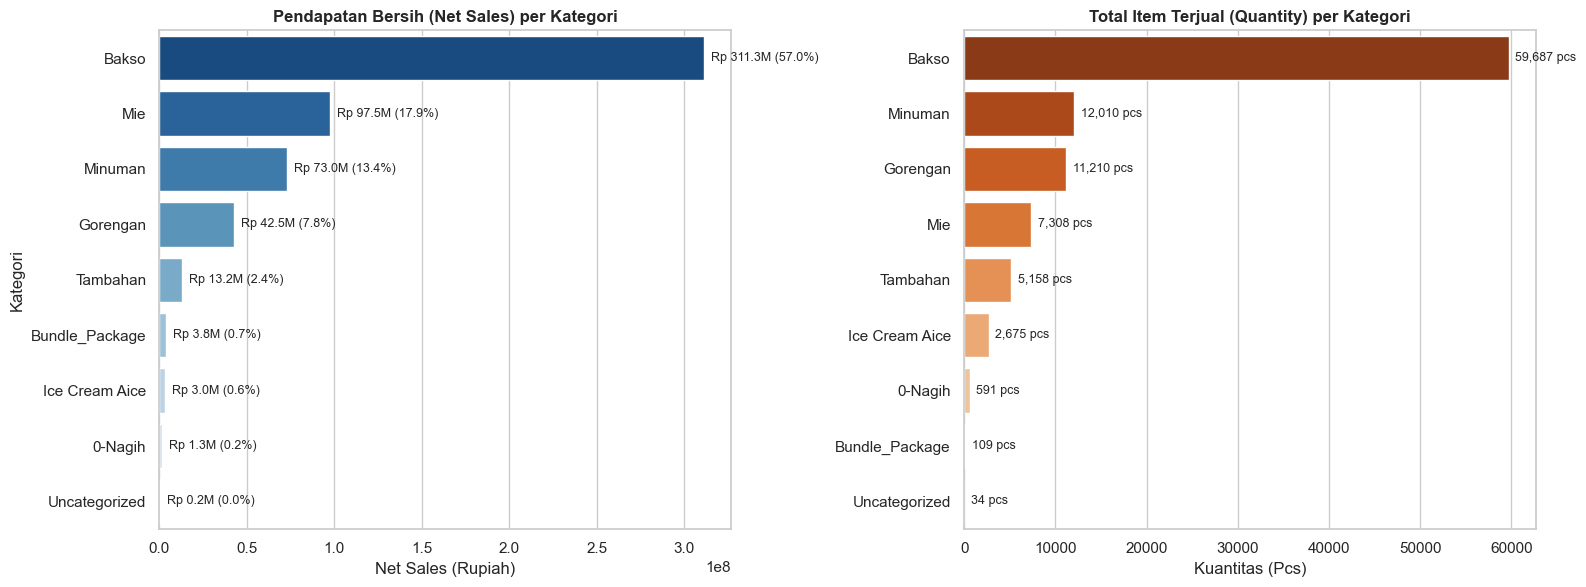

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafik 1: Net Sales per Kategori
sns.barplot(data=category_summary, x='Net Sales', y='Category', palette='Blues_r', ax=axes[0])
axes[0].set_title('Pendapatan Bersih (Net Sales) per Kategori', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Net Sales (Rupiah)')
axes[0].set_ylabel('Kategori')
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f'Rp {w/1e6:.1f}M ({w/total_net*100:.1f}%)',
                     (w, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

# Grafik 2: Kuantitas per Kategori
sns.barplot(data=category_summary.sort_values(by='Quantity', ascending=False), x='Quantity', y='Category', palette='Oranges_r', ax=axes[1])
axes[1].set_title('Total Item Terjual (Quantity) per Kategori', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kuantitas (Pcs)')
axes[1].set_ylabel('')
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f'{w:,.0f} pcs',
                     (w, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


## 7. Analisis Menu Terlaris (Top 10 Best Sellers - PRD FR-04)
Menu-menu terlaris ini adalah fokus utama untuk model *forecasting* penjualan harian dan penyusunan matriks resep (*Bill of Materials* - BOM).


### 7.1 Top 10 Menu Paling Banyak Terjual (Volume / Kuantitas)


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/683832205.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_qty, x='Quantity', y='Items', palette='viridis')


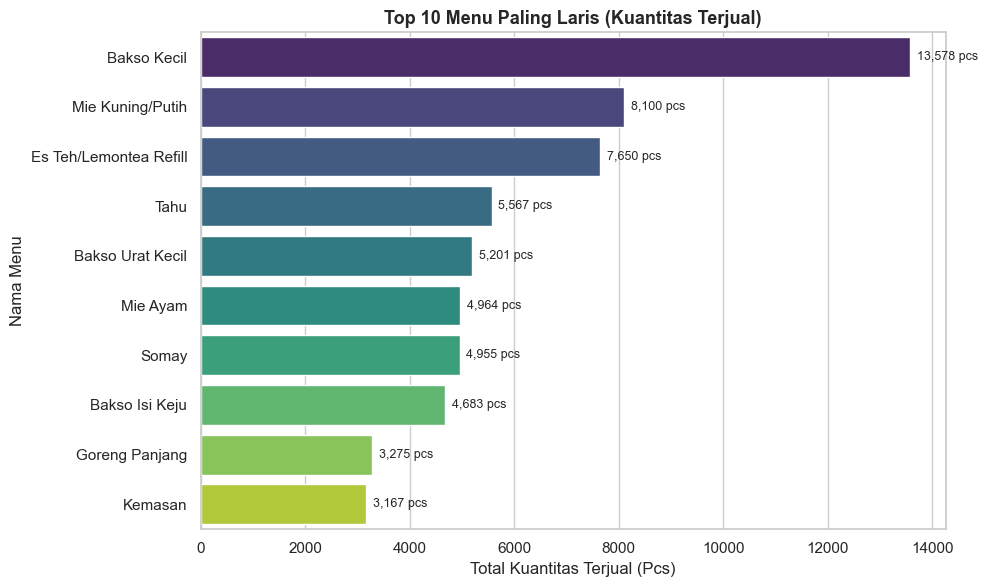

In [15]:
# Agregasi penjualan per menu
item_summary = df_clean.groupby(['Items', 'Category']).agg({
    'Quantity': 'sum',
    'Net Sales': 'sum'
}).reset_index()

# 10 Menu dengan kuantitas tertinggi
top10_qty = item_summary.sort_values(by='Quantity', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_qty, x='Quantity', y='Items', palette='viridis')
plt.title('Top 10 Menu Paling Laris (Kuantitas Terjual)', fontsize=13, fontweight='bold')
plt.xlabel('Total Kuantitas Terjual (Pcs)')
plt.ylabel('Nama Menu')
for p in plt.gca().patches:
    val = p.get_width()
    plt.gca().annotate(f'{val:,.0f} pcs', (val, p.get_y() + p.get_height() / 2),
                       ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


### 7.2 Top 10 Menu Kontributor Omset Terbesar (Net Sales)


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/776015564.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_sales, x='Net Sales', y='Items', palette='magma')


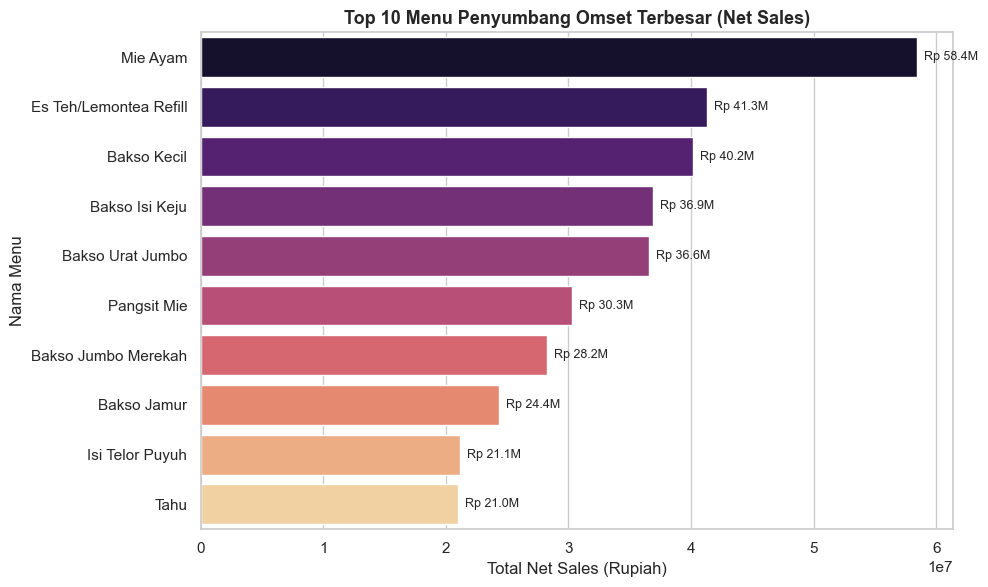

In [16]:
# 10 Menu dengan pendapatan tertinggi
top10_sales = item_summary.sort_values(by='Net Sales', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_sales, x='Net Sales', y='Items', palette='magma')
plt.title('Top 10 Menu Penyumbang Omset Terbesar (Net Sales)', fontsize=13, fontweight='bold')
plt.xlabel('Total Net Sales (Rupiah)')
plt.ylabel('Nama Menu')
for p in plt.gca().patches:
    val = p.get_width()
    plt.gca().annotate(f'Rp {val/1e6:.1f}M', (val, p.get_y() + p.get_height() / 2),
                       ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


## 8. Analisis Pola Waktu & Jam Sibuk (Time Trends & Peak Hours - PRD FR-08)
Mempelajari tren penjualan berdasarkan bulan, hari dalam seminggu, dan jam operasional untuk membantu staf dapur merencanakan persiapan bahan baku.


### 8.1 Tren Penjualan Bulanan (Monthly Net Sales)


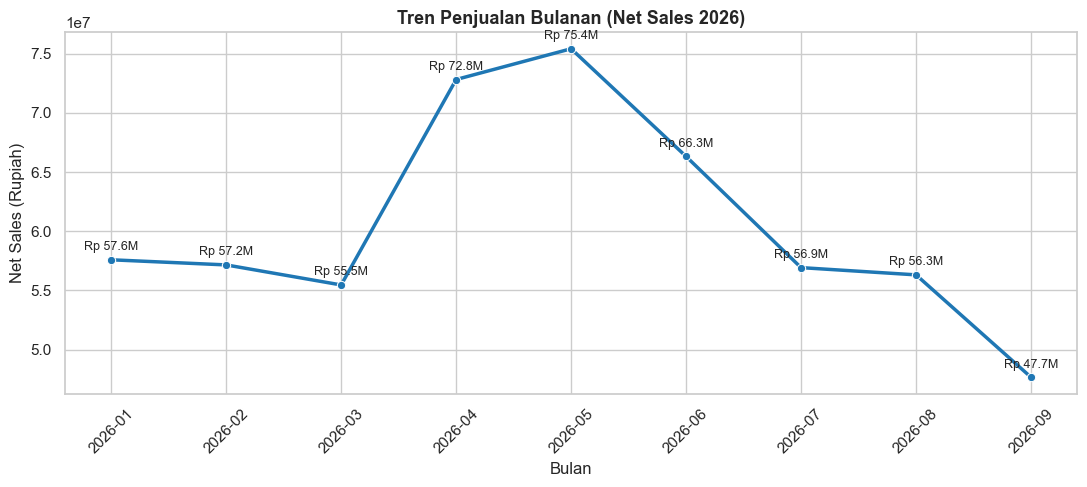

In [17]:
# Agregasi omset per bulan
monthly_sales = df_clean.groupby('Year_Month')['Net Sales'].sum().reset_index()
monthly_sales['Period_Str'] = monthly_sales['Year_Month'].astype(str)

plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly_sales, x='Period_Str', y='Net Sales', marker='o', color='#1f77b4', linewidth=2.5)
plt.title('Tren Penjualan Bulanan (Net Sales 2026)', fontsize=13, fontweight='bold')
plt.xlabel('Bulan')
plt.ylabel('Net Sales (Rupiah)')
plt.xticks(rotation=45)
for _, row in monthly_sales.iterrows():
    plt.annotate(f'Rp {row["Net Sales"]/1e6:.1f}M', (row['Period_Str'], row['Net Sales']),
                 textcoords="offset points", xytext=(0, 7), ha='center', fontsize=9)

plt.tight_layout()
plt.show()


### 8.2 Pola Penjualan Hari dalam Seminggu (Weekday vs Weekend)


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/2312593940.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=daily_sales, x='Day_Name', y='Net Sales', palette='coolwarm')


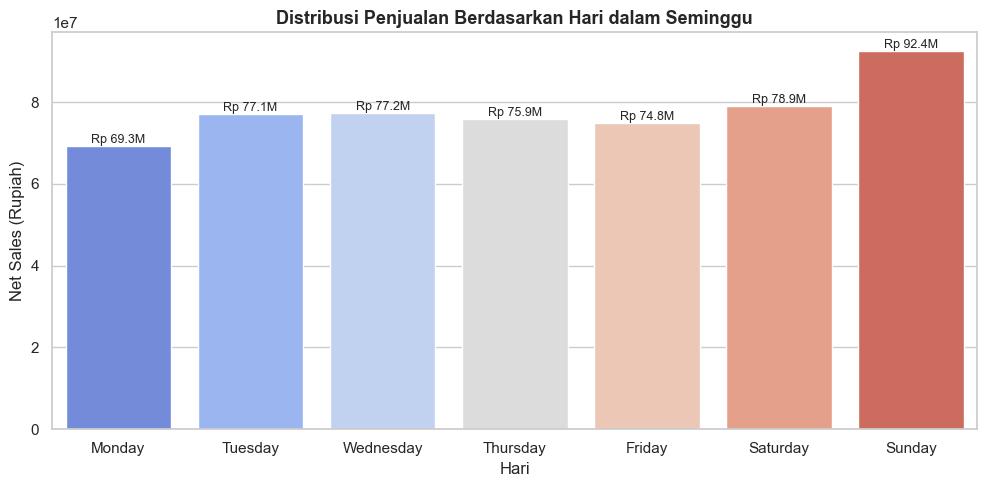

In [18]:
# Agregasi omset per hari
daily_sales = df_clean.groupby('Day_Name', observed=False)['Net Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=daily_sales, x='Day_Name', y='Net Sales', palette='coolwarm')
plt.title('Distribusi Penjualan Berdasarkan Hari dalam Seminggu', fontsize=13, fontweight='bold')
plt.xlabel('Hari')
plt.ylabel('Net Sales (Rupiah)')
for p in plt.gca().patches:
    val = p.get_height()
    plt.gca().annotate(f'Rp {val/1e6:.1f}M', (p.get_x() + p.get_width() / 2, val),
                       ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


### 8.3 Analisis Jam Operasional Tersibuk (Peak Hours)


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/1719440912.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_sales, x='Hour', y='Net Sales', palette='viridis')


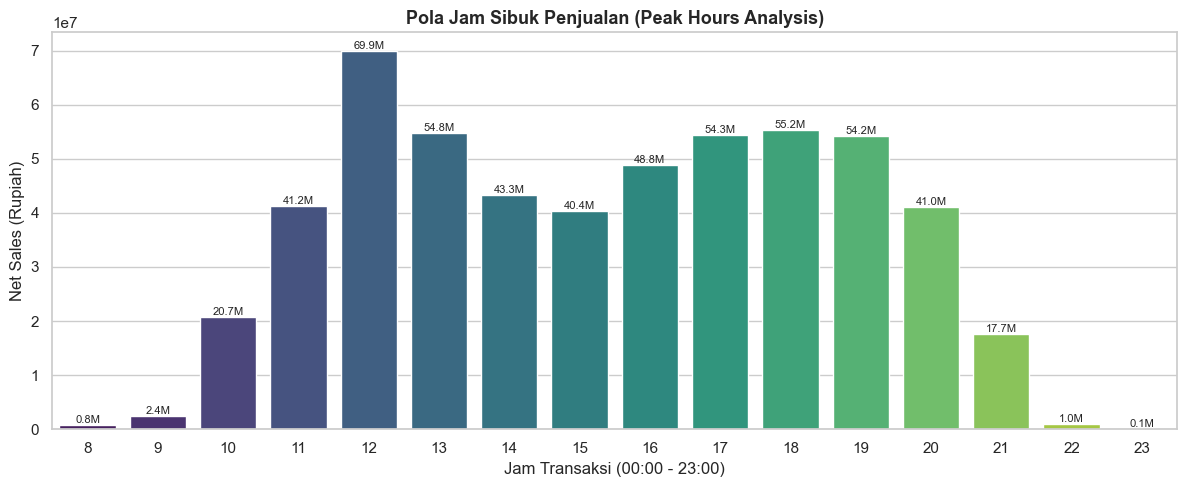

In [19]:
# Agregasi omset per jam
hourly_sales = df_clean.groupby('Hour')['Net Sales'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=hourly_sales, x='Hour', y='Net Sales', palette='viridis')
plt.title('Pola Jam Sibuk Penjualan (Peak Hours Analysis)', fontsize=13, fontweight='bold')
plt.xlabel('Jam Transaksi (00:00 - 23:00)')
plt.ylabel('Net Sales (Rupiah)')
for p in plt.gca().patches:
    val = p.get_height()
    if val > 0:
        plt.gca().annotate(f'{val/1e6:.1f}M', (p.get_x() + p.get_width() / 2, val),
                           ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


## 9. Analisis Kanal Penjualan & Metode Pembayaran
Melihat sebaran pesanan (*Dine In vs Online Delivery*) serta metode pembayaran pelanggan.


### 9.1 Proporsi Kanal Penjualan (Sales Type)


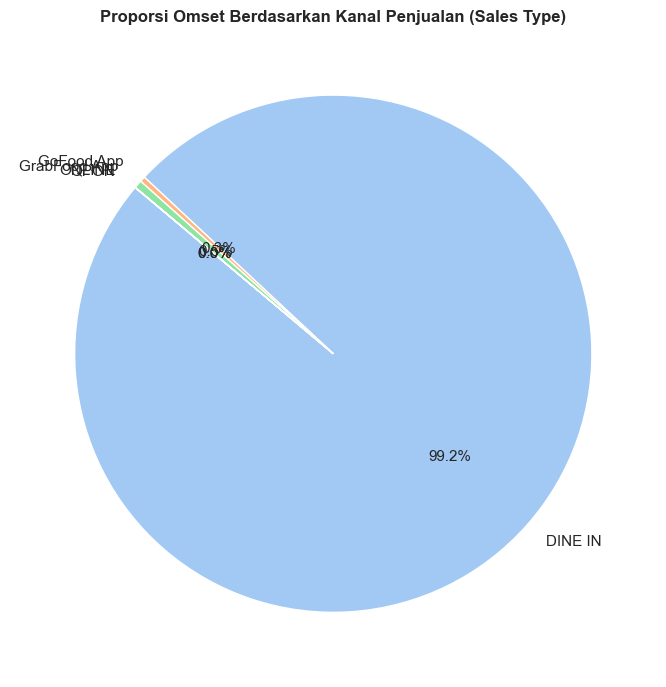

In [20]:
# Agregasi tipe penjualan
sales_channel = df_clean.groupby('Sales Type')['Net Sales'].sum().reset_index()

plt.figure(figsize=(7, 7))
plt.pie(
    sales_channel['Net Sales'],
    labels=sales_channel['Sales Type'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')
)
plt.title('Proporsi Omset Berdasarkan Kanal Penjualan (Sales Type)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 9.2 Distribusi Metode Pembayaran


/var/folders/89/z8tp_85j43s5h0jz9390swy40000gn/T/ipykernel_10018/3788166485.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_summary, x='Net Sales', y='Payment Method', palette='Blues_r')


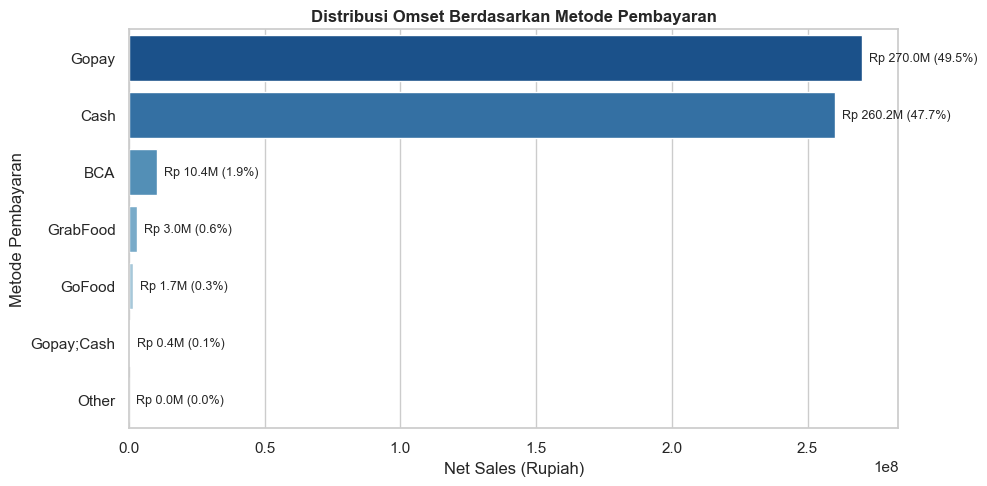

In [21]:
# Agregasi metode pembayaran
payment_summary = df_clean.groupby('Payment Method')['Net Sales'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=payment_summary, x='Net Sales', y='Payment Method', palette='Blues_r')
plt.title('Distribusi Omset Berdasarkan Metode Pembayaran', fontsize=12, fontweight='bold')
plt.xlabel('Net Sales (Rupiah)')
plt.ylabel('Metode Pembayaran')
for p in plt.gca().patches:
    val = p.get_width()
    plt.gca().annotate(f'Rp {val/1e6:.1f}M ({val/total_net*100:.1f}%)',
                       (val, p.get_y() + p.get_height() / 2),
                       ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


## 10. Agregasi Penjualan Menu Harian (Jembatan ke Forecasting - PRD FR-04)
Sesuai kebutuhan **PRD FR-04 & FR-05**, model *time-series forecasting* membutuhkan data deret waktu harian per menu untuk memproyeksikan porsi 7 hari ke depan yang nantinya dikonversi menjadi kebutuhan berat bahan baku (*Bill of Materials*).


In [22]:
# Agregasi jumlah porsi menu per tanggal
daily_menu_sales = df_clean.groupby(['Date', 'Items', 'Category'])['Quantity'].sum().reset_index()
daily_menu_sales = daily_menu_sales.sort_values(by=['Date', 'Quantity'], ascending=[True, False])

print(f"Total baris data deret waktu harian: {len(daily_menu_sales):,} baris")
print(f"Jumlah menu unik yang tercatat: {daily_menu_sales['Items'].nunique()} menu")
daily_menu_sales.head(10)


Total baris data deret waktu harian: 9,312 baris
Jumlah menu unik yang tercatat: 247 menu


,Date,Items,Category,Quantity
13,2026-01-01,Es Teh/Lemontea Refill,Minuman,51
6,2026-01-01,Bakso Kecil,Bakso,48
7,2026-01-01,Bakso Pedas,Bakso,43
29,2026-01-01,Mie Kuning/Putih,Bakso,42
34,2026-01-01,Tahu,Bakso,29
5,2026-01-01,Bakso Jumbo Merekah,Bakso,28
3,2026-01-01,Bakso Isi Keju,Bakso,23
9,2026-01-01,Bakso Urat Kecil,Bakso,19
17,2026-01-01,Goreng Panjang,Gorengan,19
25,2026-01-01,Mie Ayam,Mie,19


## 11. Kesimpulan & Ringkasan Analisis (Executive Summary)

### Data Analysis Key Findings
- **Struktur & Kelengkapan Data**: Dari 25 kolom awal file APOS, 3 kolom yang 100% kosong (`Variant`, `SKU`, `Served By`) telah berhasil dibersihkan, menghasilkan 22 kolom siap analisis.
- **Total Omset & Transaksi**: Selama periode Januari – September 2026, tercatat total **12.238 transaksi unik** dengan omset kotor **Rp 579,30 Juta** dan omset bersih **Rp 545,72 Juta** setelah diskon (Rp 31,90 Juta) dan refund (Rp 1,68 Juta).
- **Rata-rata Nilai Belanja (AOV)**: Nilai rata-rata per transaksi adalah **Rp 44.592** dengan rata-rata **~5.2 item** per struk belanja.
- **Kategori Paling Dominan**: Kategori **Bakso** menyumbang **57,0% omset (Rp 311,27 Juta)**, disusul oleh **Mie (17,9%)** dan **Minuman (13,4%)**.
- **Hero Products (Best Sellers)**: Menu dengan volume konsumsi harian tertinggi adalah **Bakso Kecil (13.578 pcs)**, **Mie Kuning/Putih (8.100 pcs)**, dan **Es Teh/Lemontea Refill (7.650 pcs)**.
- **Pola Jam Sibuk (Peak Hours)**: Terjadi pada jam makan siang (**12:00 - 14:00**) dan jam makan malam (**18:00 - 20:00**), dengan volume transaksi melonjak signifikan pada akhir pekan (Sabtu & Minggu).
- **Kanal & Pembayaran**: Penjualan didominasi oleh kanal **DINE IN**, dan metode pembayaran non-tunai (Gopay/QRIS) menjadi yang paling dominan.

### Insights or Next Steps
- **Input untuk Model Forecasting (PRD FR-04)**: Menggunakan tabel deret waktu harian menu (`daily_menu_sales`) sebagai basis data latih model prediksi penjualan porsi 7 hari ke depan.
- **Penyusunan Matriks Resep / BOM (PRD FR-05)**: Menyusun matriks berat bahan baku (daging sapi, tepung, bumbu kaldu, mie, dll.) untuk mengonversi porsi menu hasil forecasting menjadi "Daftar Belanja Besok Pagi".
- **Optimasi Operasional Dapur**: Memastikan persiapan bahan baku setengah jadi lebih awal sebelum jam sibuk makan siang (11:30) dan malam (17:30), serta menambah kuota belanja bahan untuk akhir pekan.
